In [141]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance



In [61]:
df = pd.read_csv("../data/bank-full.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [63]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


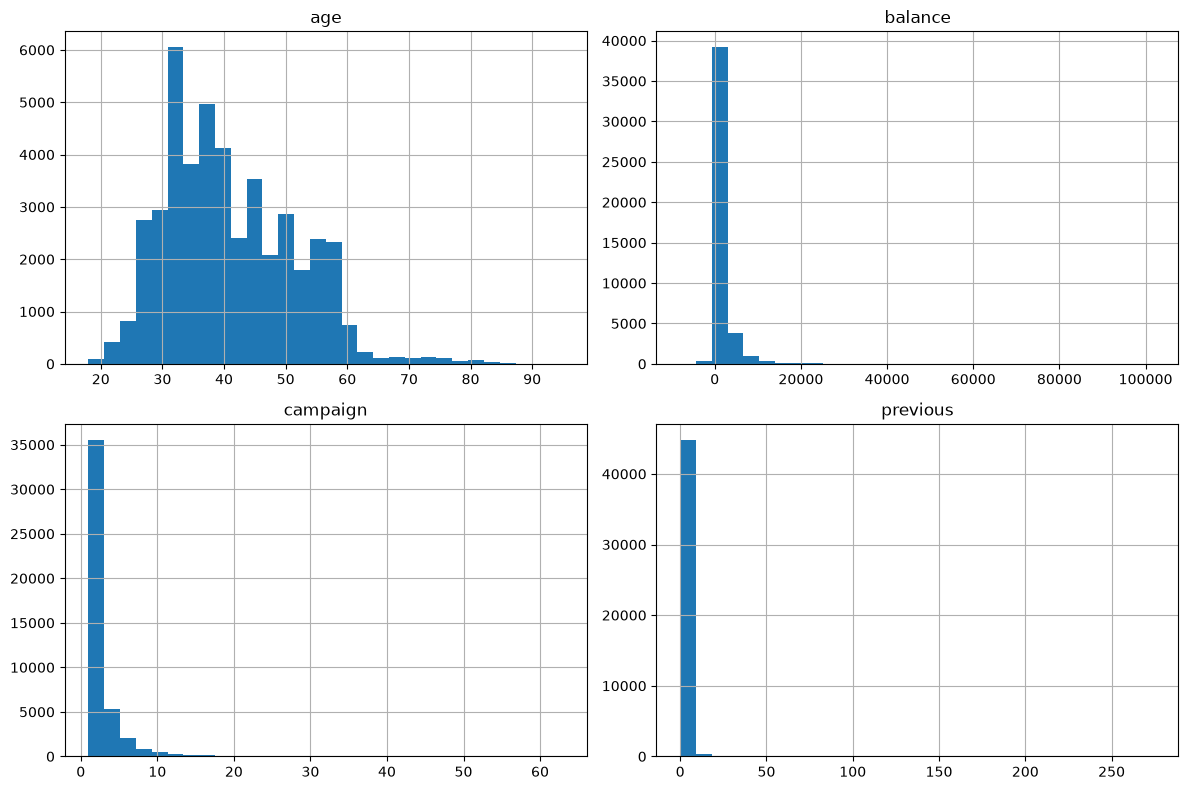

In [64]:
columns = ["age", "balance", "campaign", "previous"]

df[columns].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

<Axes: xlabel='balance'>

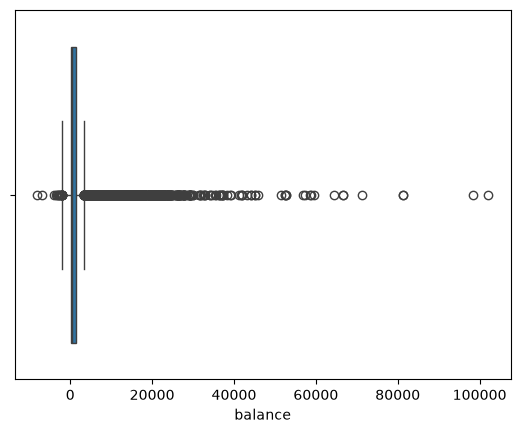

In [65]:
sns.boxplot(data=df,x="balance")

In [66]:
numerical_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numerical:", numerical_cols.tolist())
print("Categorical:", categorical_cols.tolist())

Numerical: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


C:\Users\mariam\AppData\Local\Temp\ipykernel_14052\3771475687.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [67]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [68]:
df["y"].value_counts(normalize=True) * 100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

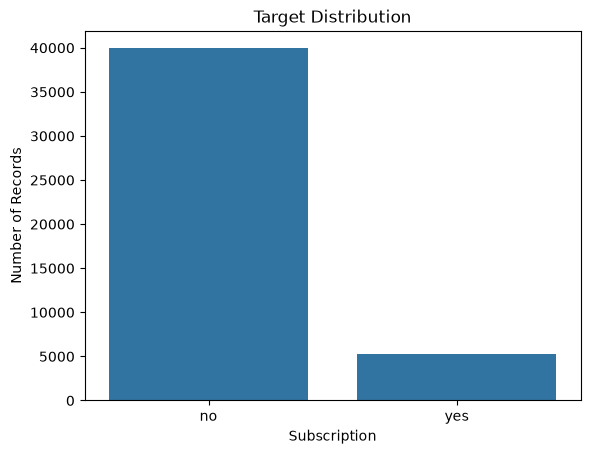

In [69]:
sns.countplot(data=df, x="y")

plt.title("Target Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Records")

plt.show()

In [70]:
pd.crosstab(df["housing"], df["y"])

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


In [71]:
pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

y,no,yes
housing,,
no,83.297645,16.702355
yes,92.300040,7.699960


Customers without housing loans show a higher subscription rate (16.70%) compared to customers with housing loans (7.70%).




In [72]:
df.groupby("y")["balance"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,1303.714969,2974.195473,-8019.0,58.0,417.0,1345.0,102127.0
yes,5289.0,1804.267915,3501.104777,-3058.0,210.0,733.0,2159.0,81204.0


In [73]:
df["balance_group"] = pd.qcut(
    df["balance"],
    q=5,
    duplicates="drop"
)

df["balance_group"].value_counts().sort_index()

balance_group
(-8019.001, 22.0]     9053
(22.0, 272.0]         9060
(272.0, 701.0]        9017
(701.0, 1859.0]       9039
(1859.0, 102127.0]    9042
Name: count, dtype: int64

In [74]:
balance_analysis = (
    df.groupby("balance_group", observed=True)["y"]
    .agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )
)

balance_analysis["subscription_rate"] = (
    balance_analysis["subscribers"]
    / balance_analysis["total_customers"] * 100
)

balance_analysis

,total_customers,subscribers,subscription_rate
balance_group,,,
"(-8019.001, 22.0]",9053,630,6.959019
"(22.0, 272.0]",9060,906,10.000000
"(272.0, 701.0]",9017,1056,11.711212
"(701.0, 1859.0]",9039,1217,13.463879
"(1859.0, 102127.0]",9042,1480,16.368060


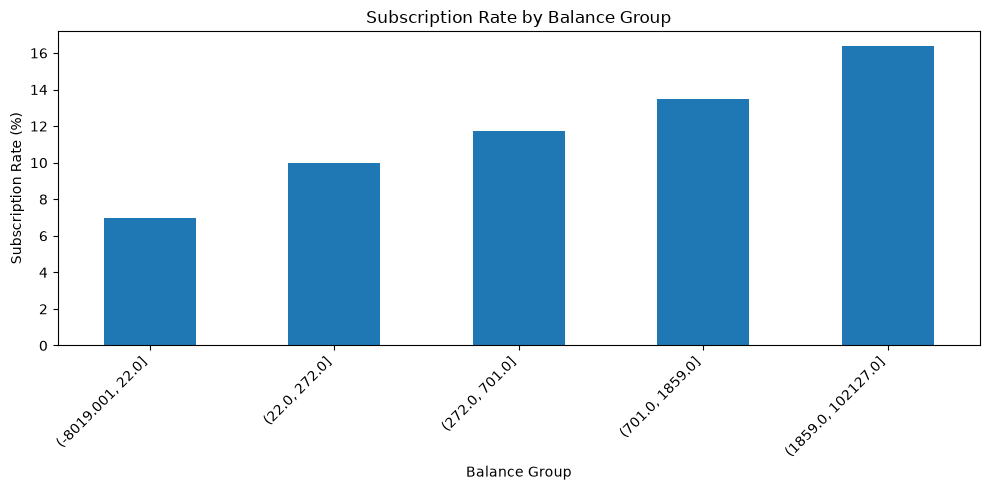

In [75]:
import matplotlib.pyplot as plt

balance_analysis["subscription_rate"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Subscription Rate by Balance Group")
plt.xlabel("Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Customers were divided into five approximately equal-sized groups based on account balance.

Subscription rates increased consistently across the balance groups.

The lowest balance group had a subscription rate of 6.96%, compared to 16.37% in the highest balance group.

The highest balance group showed approximately 2.35 times the subscription rate of the lowest group.

balance will be retained as a candidate predictive feature for the initial classification model.


In [76]:
pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

y,no,yes
loan,,
no,87.344273,12.655727
yes,93.318609,6.681391


Customers without personal loans have a subscription rate of 12.66%.

Customers with personal loans have a subscription rate of 6.68%.

A similar negative association was observed for housing loans.


In [77]:
loan_balance_analysis = (
    df.groupby(
        ["balance_group", "loan"],
        observed=True
    )["y"]
    .agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )
)

loan_balance_analysis

total_customers  subscribers
balance_group      loan                              
(-8019.001, 22.0]  no               6941          505
                   yes              2112          125
(22.0, 272.0]      no               7478          803
                   yes              1582          103
(272.0, 701.0]     no               7586          960
                   yes              1431           96
(701.0, 1859.0]    no               7804         1129
                   yes              1235           88
(1859.0, 102127.0] no               8158         1408
                   yes               884           72

In [78]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[18, 30, 40, 50, 60, 100],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True
)

df["age_group"].value_counts().sort_index()

age_group
18-30     7030
31-40    17687
41-50    11239
51-60     8067
60+       1188
Name: count, dtype: int64

In [79]:
age_analysis = (
    df.groupby(
        ["age_group"],
        observed=True
    )["y"]
    .agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )
)
age_analysis["subscription_rate"] = (
    age_analysis["subscribers"]
    / age_analysis["total_customers"]
) * 100

age_analysis

,total_customers,subscribers,subscription_rate
age_group,,,
18-30,7030,1145,16.287340
31-40,17687,1812,10.244813
41-50,11239,1019,9.066643
51-60,8067,811,10.053304
60+,1188,502,42.255892


In [80]:
senior_customers = df[df["age"] > 60].copy()

senior_customers["age_group_detailed"] = pd.cut(
    senior_customers["age"],
    bins=[60, 70, 80, 100],
    labels=["61-70", "71-80", "81-100"]
)

senior_analysis = (
    senior_customers.groupby(
        "age_group_detailed",
        observed=True
    )["y"]
    .agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )
)

senior_analysis["subscription_rate"] = (
    senior_analysis["subscribers"]
    / senior_analysis["total_customers"]
) * 100

senior_analysis

,total_customers,subscribers,subscription_rate
age_group_detailed,,,
61-70,701,284,40.513552
71-80,388,175,45.103093
81-100,99,43,43.434343


In [81]:
pd.crosstab(
    df["age_group"],
    df["housing"],
    normalize="index"
) * 100

housing,no,yes
age_group,,
18-30,42.389758,57.610242
31-40,36.490077,63.509923
41-50,43.233384,56.766616
51-60,58.038924,41.961076
60+,93.097643,6.902357


In [82]:
pd.crosstab(
    df["age_group"],
    df["loan"],
    normalize="index"
) * 100

loan,no,yes
age_group,,
18-30,83.229018,16.770982
31-40,84.581896,15.418104
41-50,83.085684,16.914316
51-60,82.434610,17.565390
60+,98.316498,1.683502


Customers aged 60+ have the highest subscription rate (42.26%) and the lowest loan rates:

Housing Loan: 6.90%

Personal Loan: 1.68%

This suggests that lower financial obligations may be associated with higher subscription rates among older customers.

However, this relationship does not prove causation.

ML Decision: Retain age, housing, and loan as candidate features.

In [83]:
job_analysis = (
    df.groupby("job")["y"]
    .agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )
)

job_analysis["subscription_rate"] = (
    job_analysis["subscribers"]
    / job_analysis["total_customers"]
) * 100

job_analysis.sort_values("subscription_rate", ascending=False)

,total_customers,subscribers,subscription_rate
job,,,
student,938,269,28.678038
retired,2264,516,22.791519
unemployed,1303,202,15.502686
management,9458,1301,13.755551
admin.,5171,631,12.202669
self-employed,1579,187,11.842939
unknown,288,34,11.805556
technician,7597,840,11.056996
services,4154,369,8.883004


Students (28.68%), retired customers (22.79%), and unemployed customers (15.50%) have the highest subscription rates.

Job type appears to be associated with subscription behavior, potentially reflecting different financial needs and preferences.

ML Decision: Retain job as a candidate feature.

In [84]:
pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

y,no,yes
poutcome,,
failure,87.390329,12.609671
other,83.315217,16.684783
success,35.274653,64.725347
unknown,90.838497,9.161503


Customers with a successful previous campaign outcome have a significantly higher subscription rate (64.73%) compared to customers with unknown outcomes (9.16%).

In [85]:
df["poutcome"].value_counts()

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

In [86]:
df["contacted_before"] = df["previous"] > 0

pd.crosstab(
    df["contacted_before"],
    df["y"],
    normalize="index"
) * 100

y,no,yes
contacted_before,,
False,90.842669,9.157331
True,76.928667,23.071333


In [87]:
pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

y,no,yes
education,,
primary,91.373522,8.626478
secondary,89.440565,10.559435
tertiary,84.993610,15.006390
unknown,86.429725,13.570275


In [88]:
df.isnull().sum()

age                 0
job                 0
marital             0
education           0
default             0
balance             0
housing             0
loan                0
contact             0
day                 0
month               0
duration            0
campaign            0
pdays               0
previous            0
poutcome            0
y                   0
balance_group       0
age_group           0
contacted_before    0
dtype: int64

In [89]:
(df == "unknown").sum()

age                     0
job                   288
marital                 0
education            1857
default                 0
balance                 0
housing                 0
loan                    0
contact             13020
day                     0
month                   0
duration                0
campaign                0
pdays                   0
previous                0
poutcome            36959
y                       0
balance_group           0
age_group               0
contacted_before        0
dtype: int64

In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y', 'balance_group', 'age_group',
       'contacted_before'],
      dtype='str')

In [92]:
drop_cols = [
    "duration", "campaign",
    "contact", "day", "month",
    "balance_group", "age_group",
    "contacted_before", "y"
]

X = df.drop(columns=drop_cols)
y = df["y"]

In [93]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [94]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [95]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (31647, 11)
Validation: (6782, 11)
Test: (6782, 11)


In [96]:
print(X_train["job"].mode()[0])
print(X_train["education"].mode()[0])

blue-collar
secondary


In [97]:
mode_imputer = SimpleImputer(
    missing_values="unknown",
    strategy="most_frequent"
)

columns = ["job", "education"]

X_train[columns] = mode_imputer.fit_transform(
    X_train[columns]
)
X_val[columns] = mode_imputer.transform(
    X_val[columns]
)

X_test[columns] = mode_imputer.transform(
    X_test[columns]
)

In [98]:
(X_train[columns] == "unknown").sum()

job          0
education    0
dtype: int64

In [99]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical_cols)

['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']


C:\Users\mariam\AppData\Local\Temp\ipykernel_14052\2405804326.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [100]:

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [101]:
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)
print("Before Encoding:", X_train[categorical_cols].shape)
print("After Encoding:", X_train_encoded.shape)

Before Encoding: (31647, 7)
After Encoding: (31647, 27)


In [102]:
X_val_encoded = encoder.transform(
    X_val[categorical_cols]
)

X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

In [103]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print(numerical_cols)

['age', 'balance', 'pdays', 'previous']


In [105]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numerical_cols]
)

In [107]:
X_val_scaled = scaler.transform(
    X_val[numerical_cols]
)

X_test_scaled = scaler.transform(
    X_test[numerical_cols]
)

In [109]:

X_train_final = np.hstack([
    X_train_scaled,
    X_train_encoded
])

X_val_final = np.hstack([
    X_val_scaled,
    X_val_encoded
])

X_test_final = np.hstack([
    X_test_scaled,
    X_test_encoded
])

In [110]:
print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Training: (31647, 31)
Validation: (6782, 31)
Testing: (6782, 31)


In [112]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_final, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [113]:
y_val_proba = model.predict_proba(X_val_final)

print(y_val_proba[:5])

[[0.90121871 0.09878129]
 [0.8607015  0.1392985 ]
 [0.89829489 0.10170511]
 [0.9271693  0.0728307 ]
 [0.9590128  0.0409872 ]]


In [114]:
print(model.classes_)

['no' 'yes']


In [115]:
y_val_pred = model.predict(X_val_final)

print(y_val_pred[:10])

['no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no']


In [117]:


print("Accuracy:", accuracy_score(y_val, y_val_pred))

print("Precision:", precision_score(
    y_val, y_val_pred, pos_label="yes"
))

print("Recall:", recall_score(
    y_val, y_val_pred, pos_label="yes"
))

print("F1 Score:", f1_score(
    y_val, y_val_pred, pos_label="yes"
))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Accuracy: 0.8935417281038042
Precision: 0.6747572815533981
Recall: 0.17506297229219145
F1 Score: 0.278

Classification Report:
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      5988
         yes       0.67      0.18      0.28       794

    accuracy                           0.89      6782
   macro avg       0.79      0.58      0.61      6782
weighted avg       0.87      0.89      0.86      6782



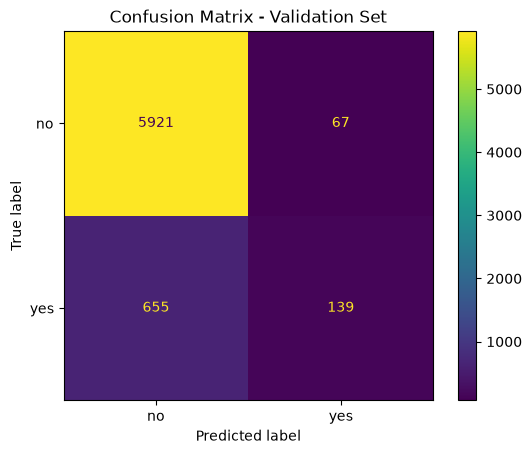

In [119]:

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred
)

plt.title("Confusion Matrix - Validation Set")
plt.show()

In [122]:
print(y_val_proba.shape)
print(y_val_proba[:3])

(6782, 2)
[[0.90121871 0.09878129]
 [0.8607015  0.1392985 ]
 [0.89829489 0.10170511]]


In [123]:
y_val_proba = model.predict_proba(X_val_final)[:, 1]

print(y_val_proba.shape)
print(y_val_proba[:3])

(6782,)
[0.09878129 0.1392985  0.10170511]


In [124]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    predictions = np.where(
        y_val_proba >= threshold,
        "yes",
        "no"
    )

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, predictions, pos_label="yes"), 3))
    print("Recall:", round(recall_score(y_val, predictions, pos_label="yes"), 3))
    print("F1:", round(f1_score(y_val, predictions, pos_label="yes"), 3))


Threshold: 0.2
Precision: 0.43
Recall: 0.31
F1: 0.36

Threshold: 0.3
Precision: 0.604
Recall: 0.213
F1: 0.315

Threshold: 0.4
Precision: 0.647
Recall: 0.196
F1: 0.301

Threshold: 0.5
Precision: 0.675
Recall: 0.175
F1: 0.278


In [125]:
k = int(len(y_val_proba) * 0.20)

print("Total customers:", len(y_val_proba))
print("Customers to target:", k)

Total customers: 6782
Customers to target: 1356


In [126]:
top_indices = np.argsort(y_val_proba)[::-1][:k]

In [127]:
top_actual = y_val.iloc[top_indices]

precision_at_20 = (top_actual == "yes").mean()

print("Precision@20%:", round(precision_at_20 * 100, 2), "%")

Precision@20%: 27.36 %


In [128]:
baseline_rate = (y_val == "yes").mean()

lift_at_20 = precision_at_20 / baseline_rate

print("Baseline Rate:", round(baseline_rate * 100, 2), "%")
print("Precision@20%:", round(precision_at_20 * 100, 2), "%")
print("Lift@20%:", round(lift_at_20, 2))

Baseline Rate: 11.71 %
Precision@20%: 27.36 %
Lift@20%: 2.34


In [130]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [131]:
rf_proba = rf_model.predict_proba(X_val_final)[:, 1]

print(rf_proba[:10])

[0.06582565 0.1814534  0.06919296 0.06518229 0.07559866 0.11918957
 0.31912244 0.05510628 0.0362869  0.11096481]


In [132]:
rf_sorted_indices = np.argsort(rf_proba)[::-1]

rf_top_indices = rf_sorted_indices[:k]

rf_top_actual = y_val.iloc[rf_top_indices]

rf_precision_at_20 = (rf_top_actual == "yes").mean()

print("Random Forest Precision@20%:",
      round(rf_precision_at_20 * 100, 2), "%")

print("Logistic Regression Precision@20%:",
      round(precision_at_20 * 100, 2), "%")

Random Forest Precision@20%: 30.09 %
Logistic Regression Precision@20%: 27.36 %


In [133]:
rf_lift_at_20 = rf_precision_at_20 / baseline_rate

print("Random Forest Lift@20%:", round(rf_lift_at_20, 2))

Random Forest Lift@20%: 2.57


In [134]:
rf_pred = rf_model.predict(X_val_final)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "Precision@20%"],
    "Logistic Regression": [
        accuracy_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred, pos_label="yes"),
        recall_score(y_val, y_val_pred, pos_label="yes"),
        f1_score(y_val, y_val_pred, pos_label="yes"),
        precision_at_20
    ],
    "Random Forest": [
        accuracy_score(y_val, rf_pred),
        precision_score(y_val, rf_pred, pos_label="yes"),
        recall_score(y_val, rf_pred, pos_label="yes"),
        f1_score(y_val, rf_pred, pos_label="yes"),
        rf_precision_at_20
    ]
})

results.round(3)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.894,0.894
1,Precision,0.675,0.697
2,Recall,0.175,0.165
3,F1,0.278,0.267
4,Precision@20%,0.274,0.301


In [136]:
lr_ap = average_precision_score(
    y_val == "yes", y_val_proba
)

rf_ap = average_precision_score(
    y_val == "yes", rf_proba
)

print("Logistic Regression AP:", round(lr_ap, 3))
print("Random Forest AP:", round(rf_ap, 3))

Logistic Regression AP: 0.348
Random Forest AP: 0.397


In [ ]:
feature_names = (
    numerical_cols +
    encoder.get_feature_names_out(categorical_cols).tolist()
)

print(feature_names)
print(len(feature_names))

['age', 'balance', 'pdays', 'previous', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_divorced', 'marital_married', 'marital_single', 'education_primary', 'education_secondary', 'education_tertiary', 'default_no', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']
31


In [145]:
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance

def custom_ap_score(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    y_binary = (y == "yes").astype(int)

    return average_precision_score(y_binary, probabilities)

In [146]:
importance = permutation_importance(
    rf_model,
    X_val_final,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)


ValueError: pos_label=1 is not a valid label: It should be one of ['no' 'yes']